# Customer Churn Prediction
**Sawaal:** Telecom company ke kaunse customers company chhod denge (churn), aur unhe rokne ke liye company kya kare?

**Kaise use karein:** har cell ko upar se neeche, ek-ek karke `Shift + Enter` se chalao. Har code se pehle likha hai ki wo kya karta hai. **Aage badhne se pehle har cell ka output padho aur samjho.**

---
## Setup
1. Kaggle pe **"Telco Customer Churn"** (by blastchar) dataset download karo.
2. Zip kholo, aur `WA_Fn-UseC_-Telco-Customer-Churn.csv` ko Colab ke left side 📁 icon me upload karo.

---
# 📅 DIN 1: Data samjho (EDA = Exploratory Data Analysis)
### Step 1: Libraries import karo
- `pandas` se data tables, `numpy` se maths
- `matplotlib` aur `seaborn` se graphs

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Data load karo
`shape` batata hai (rows, columns). **(7043, 21)** aana chahiye, yaani 7043 customers aur har customer ki 21 jaankari.

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Step 3: Columns ka type dekho
Dhyan do: `TotalCharges` ka type **object / str** (text) dikhega, jabki ye number hona chahiye. **Ye data ki pehli gadbad hai.**

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Step 4: Data saaf karo (Data Cleaning)
- `TotalCharges` ko number me badlo. Jahan khaali jagah hai, wahan `NaN` (missing) ban jayega.
- Missing wali rows (sirf ~11) hata do.
- `customerID` hata do, kyunki ID se koi pattern nahi seekha ja sakta.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])

df = df.dropna()
df = df.drop("customerID", axis=1)
print("\nNaya shape:", df.shape)

Missing values:
 TotalCharges    11
dtype: int64

Naya shape: (7032, 20)


### Step 5: Kitne customers chhod rahe hain?
⚠️ **Bahut important (interview question):** lagbhag 73% "No" aur 27% "Yes" aayega. Isse **imbalanced data** kehte hain.
Agar model sabko "No" bol de, tab bhi 73% accuracy aa jayegi. **Isliye sirf accuracy pe bharosa nahi karenge; Recall, F1 aur ROC-AUC bhi dekhenge.**

Churn
No     0.734
Yes    0.266
Name: proportion, dtype: float64


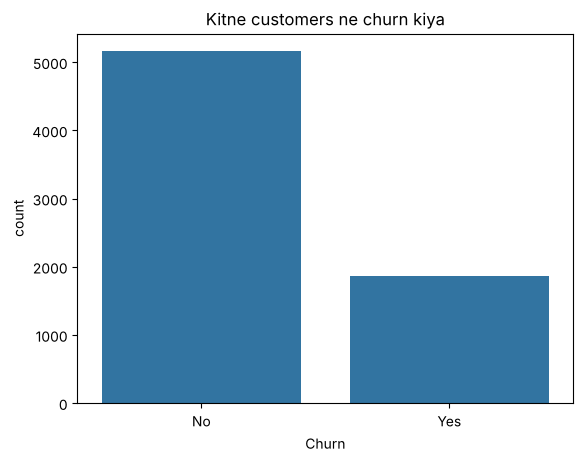

In [5]:
print(df["Churn"].value_counts(normalize=True).round(3))
sns.countplot(x="Churn", data=df)
plt.title("Kitne customers ne churn kiya")
plt.show()

### Step 6: Contract type vs Churn
Kya plan ka type churn pe asar karta hai?

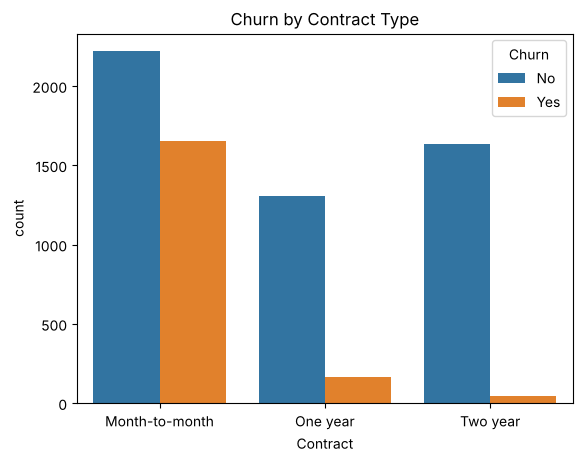

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


In [6]:
sns.countplot(x="Contract", hue="Churn", data=df)
plt.title("Churn by Contract Type")
plt.show()

# Har contract type me churn ka % :
print((df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()) * 100).round(1))

### Step 7: Tenure (kitne mahine se customer hai) vs Churn

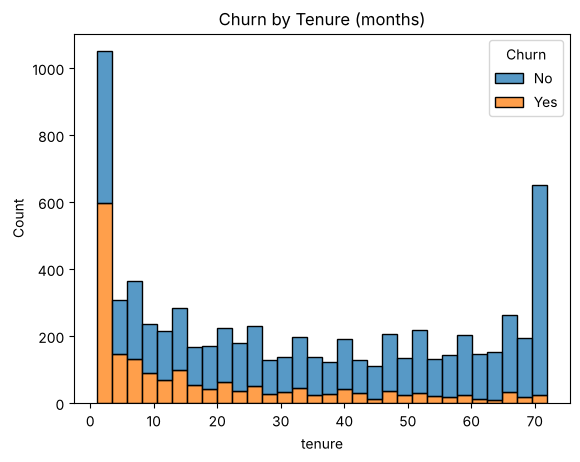

In [7]:
sns.histplot(data=df, x="tenure", hue="Churn", multiple="stack", bins=30)
plt.title("Churn by Tenure (months)")
plt.show()

### Step 8: Monthly bill vs Churn

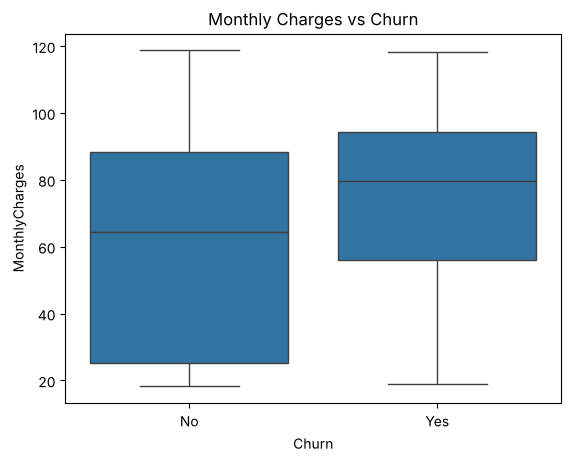

In [8]:
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Monthly Charges vs Churn")
plt.show()

### Step 9: Internet service aur payment method vs Churn

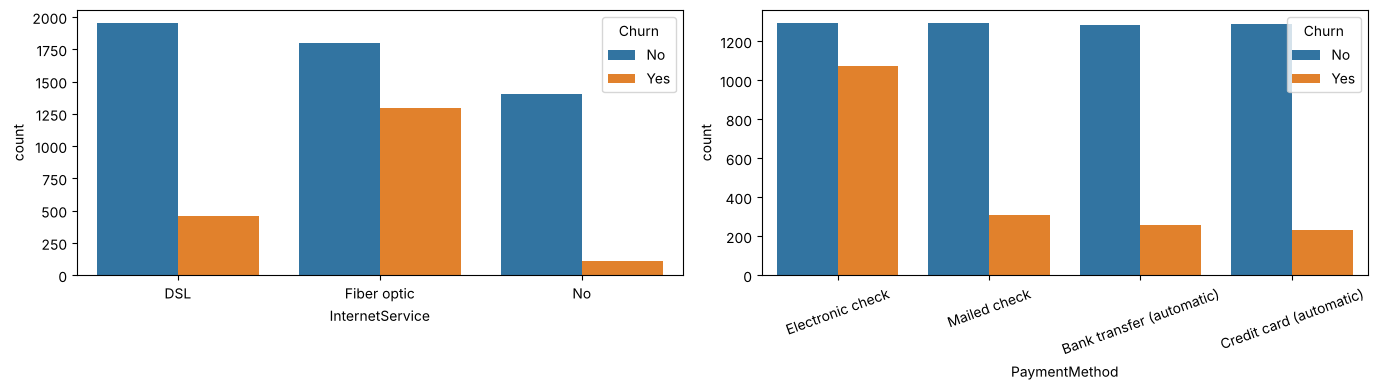

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(x="InternetService", hue="Churn", data=df, ax=axes[0])
sns.countplot(x="PaymentMethod", hue="Churn", data=df, ax=axes[1])
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### 📝 Din 1: Key Findings
1. **26.6%** customers churn karte hain (1,869 / 7,032). Data **imbalanced** hai, isliye sirf accuracy kaafi nahi.
2. **Contract:** Month-to-month me **42.7%** churn, One year me 11.3%, Two year me sirf **2.8%**.
3. **Tenure:** pehle 12 mahine ke customers me **47.7%** churn; 4+ saal (49–72 mahine) wale sirf 9.5%.
4. **Bill aur services:** churn karne walon ka median monthly bill **79.65** hai, rukne walon ka 64.45. **Fiber optic** users me 41.9% churn (DSL: 19.0%). **Electronic check** se pay karne walon me 45.3% churn (auto-pay: ~15–17%). Tech Support / Online Security na lene walon me ~42% churn.

---
# 📅 DIN 2: Model banao
### Step 10: Text ko numbers me badlo (Encoding)
ML model sirf numbers samajhta hai.
- `Churn`: Yes → 1, No → 0
- Baaki text columns (jaise Contract) ke liye **one-hot encoding** (`get_dummies`): har option ka alag 0/1 column banta hai.
  Example: Contract → `Contract_One year`, `Contract_Two year` (agar dono 0 hain to matlab Month-to-month).

In [10]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

X = pd.get_dummies(df.drop("Churn", axis=1), drop_first=True)  # inputs (features)
y = df["Churn"]                                                 # jo predict karna hai (target)

print("Features:", X.shape[1])
X.head()

Features: 30


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


### Step 11: Train / Test me baanto
- **80% data** se model seekhega (train), **20%** pe hum check karenge (test). Ye wo data hai jo model ne kabhi nahi dekha.
- Kyun? Jaise exam me wahi sawaal aaye jo ratt liye the, to pata nahi chalta ki sach me samjha ya nahi. Test data naye sawaal hain.
- `stratify=y`: train aur test dono me churn ka % same (~27%) rahe.
- `random_state=42`: har baar same split aaye, taaki results repeat ho sakein.

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (5625, 30)  Test: (1407, 30)


### Step 12: Scaling (Logistic Regression ke liye)
`tenure` 0–72 hai aur `TotalCharges` 0–8000. Logistic Regression ko sab columns ek jaise scale pe chahiye.
`StandardScaler` har column ko average 0 aur spread 1 bana deta hai.
⚠️ Scaler sirf **train** data pe `fit` karte hain, taaki test data ki jaankari leak na ho (interview question: **data leakage**).

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

### Step 13: Model 1, Logistic Regression
Simple model jo har customer ke churn karne ki **probability** (0 se 1) deta hai. 0.5 se zyada ho to "churn karega".
`class_weight="balanced"`: churn wale customers kam hain, isliye unki galti ko zyada importance do. Isse recall badhta hai.

In [13]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000, class_weight="balanced")
lr.fit(X_train_s, y_train)

lr_pred = lr.predict(X_test_s)
lr_prob = lr.predict_proba(X_test_s)[:, 1]

### Step 14: Model 2, Random Forest
Bahut saare **decision trees** (if-else jaise sawaalon ki chain) banata hai aur sabka vote leta hai. Aksar zyada accurate hota hai.
Isko scaling ki zaroorat nahi.

In [14]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced", random_state=42)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]

### Step 15: Dono models ko check karo (Evaluation)
**Ye sab yaad karna hai (interview me pakka poochenge):**
| Metric | Matlab (churn ke context me) |
|---|---|
| **Accuracy** | Kitne % predictions sahi the |
| **Precision** | Jinko model ne "churn karega" bola, unme se kitne sach me gaye |
| **Recall** | Jo sach me gaye, unme se kitno ko model ne pakda |
| **F1** | Precision aur recall ka balance (harmonic mean) |
| **ROC-AUC** | Model churn aur non-churn ko kitna achhe se alag karta hai (0.5 = tukka, 1 = perfect) |

Churn me **recall zyada important** hai: jaane wale customer ko miss karna mehnga padta hai.

In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy":  [accuracy_score(y_test, lr_pred),  accuracy_score(y_test, rf_pred)],
    "Precision": [precision_score(y_test, lr_pred), precision_score(y_test, rf_pred)],
    "Recall":    [recall_score(y_test, lr_pred),    recall_score(y_test, rf_pred)],
    "F1":        [f1_score(y_test, lr_pred),        f1_score(y_test, rf_pred)],
    "ROC-AUC":   [roc_auc_score(y_test, lr_prob),   roc_auc_score(y_test, rf_prob)],
}).round(3)
results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.726,0.491,0.797,0.608,0.835
1,Random Forest,0.739,0.506,0.802,0.620,0.838


### Step 16: Confusion Matrix
4 dabbe: sahi pakde, galat pakde, chhoot gaye, sahi chhode.
- Neeche-baaye (actual 1, predicted 0) = **jo customers chale gaye par model ne miss kar diye** (ye kam hone chahiye)

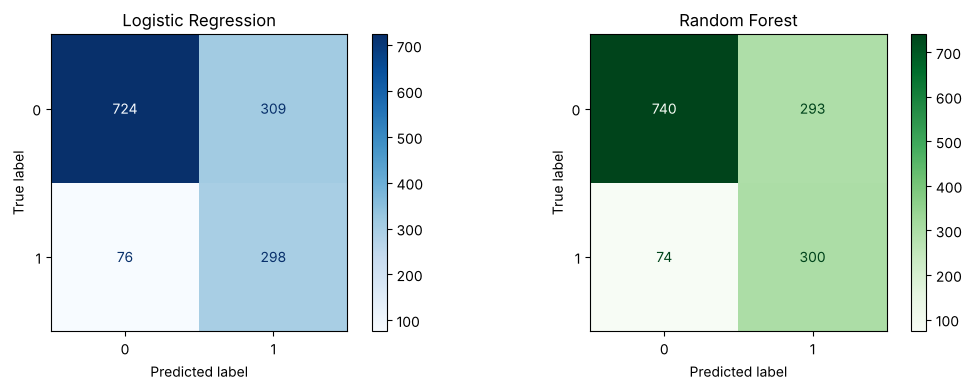

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, lr_pred, ax=axes[0], cmap="Blues")
axes[0].set_title("Logistic Regression")
ConfusionMatrixDisplay.from_predictions(y_test, rf_pred, ax=axes[1], cmap="Greens")
axes[1].set_title("Random Forest")
plt.tight_layout()
plt.show()

### Step 17: ROC Curve
Jitna curve upar-baayi taraf jhuka ho, utna accha model. Beech ki seedhi line = tukka (AUC 0.5).

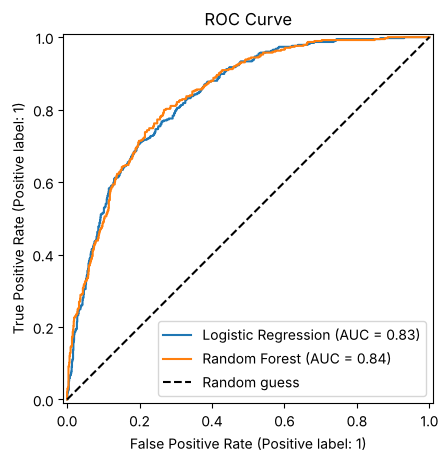

In [17]:
from sklearn.metrics import RocCurveDisplay

ax = plt.gca()
RocCurveDisplay.from_predictions(y_test, lr_prob, name="Logistic Regression", ax=ax)
RocCurveDisplay.from_predictions(y_test, rf_prob, name="Random Forest", ax=ax)
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.legend()
plt.title("ROC Curve")
plt.show()

### 📝 Din 2: Model Results (test set: 1,407 customers)
| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.726 | 0.491 | 0.797 | 0.608 | 0.835 |
| **Random Forest** | **0.739** | **0.506** | **0.802** | **0.620** | **0.838** |

- **Final model: Random Forest.** Har metric me thoda behtar hai.
- **Recall 0.80:** jo 374 customers sach me gaye, unme se **300 ko model ne pehle hi pakad liya**; sirf 74 miss hue.
- **Trade-off:** precision ~0.51 hai, yaani "churn karega" bole gaye customers me se aadhe ruk jaate. Churn me ye theek hai: ek retention offer dena sasta hai, customer khona mehnga.
- Accuracy (0.74) "sabko No bolo" (0.73) se zyada nahi lagti, isliye humne F1 aur ROC-AUC pe focus kiya.

---
# 📅 DIN 3: Insights + GitHub
### Step 18: Kaunse features sabse important hain?
Random Forest batata hai ki churn predict karne me kaunsi jaankari sabse zyada kaam aayi.

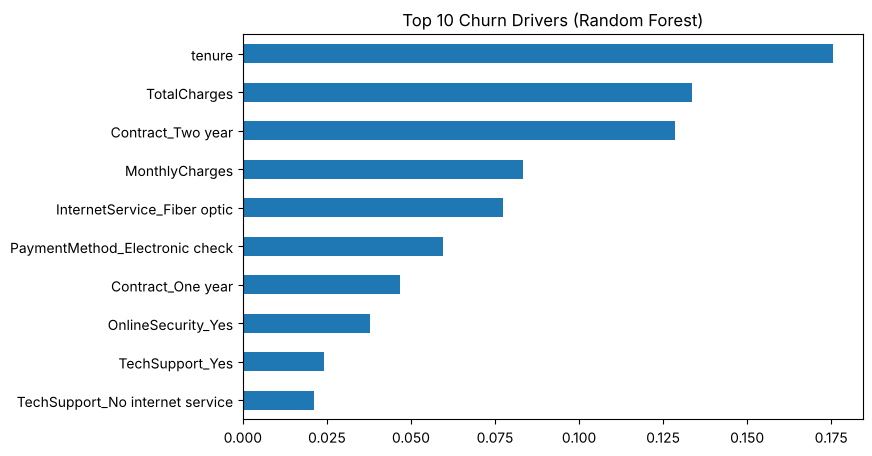

In [18]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.head(10).plot(kind="barh", figsize=(8, 5))
plt.gca().invert_yaxis()
plt.title("Top 10 Churn Drivers (Random Forest)")
plt.show()

### Step 19: High-risk customers dhoondo
Test data me jin customers ki churn probability 70% se zyada hai, wo company ke liye **"high risk"** hain. Inko turant offer dena chahiye.

In [19]:
risk = X_test.copy()
risk["churn_probability"] = rf_prob
high_risk = risk[risk["churn_probability"] > 0.7]
print(f"High-risk customers: {len(high_risk)} out of {len(risk)}")
print("Unka average tenure:", round(high_risk['tenure'].mean(), 1), "months")
print("Unka average monthly bill:", round(high_risk['MonthlyCharges'].mean(), 1))

High-risk customers: 313 out of 1407
Unka average tenure: 7.9 months
Unka average monthly bill: 75.2


### 📝 Din 3: Business Recommendations
**Top churn drivers (Random Forest):** tenure, TotalCharges, Two-year contract, MonthlyCharges, Fiber optic internet, Electronic check payment.

**High-risk group:** 313 test customers ki churn probability 70% se zyada thi. Ye **sab month-to-month** pe the, average tenure sirf **7.9 mahine**, average bill **75.2**. Inme se **62%** sach me chale gaye.

1. **Contract upgrade offer:** month-to-month customers (42.7% churn) ko 1-year / 2-year plan pe discount do. Two-year me churn sirf 2.8% hai.
2. **Pehle saal ka onboarding program:** 0–12 mahine wale customers me 47.7% churn hai. Welcome offers aur check-in calls pehle saal pe focus karein.
3. **Auto-pay aur support bundle:** Electronic check users (45.3% churn) ko auto-pay pe shift karne ka incentive do, aur Fiber users ko Tech Support / Online Security bundle offer karo (inke bina ~42% churn hai).

---
### GitHub pe daalo
1. Colab me **File → Download → .ipynb** karo.
2. GitHub pe naya repo banao: `customer-churn-prediction`.
3. Notebook upload karo aur ek `README.md` banao jisme ho:
   - **Problem** (1–2 line)
   - **Dataset** (Kaggle link)
   - **Key findings** (Din 1)
   - **Results table** (Din 2 wali)
   - **Recommendations** (Din 3)
   - 2–3 graphs ke screenshots

---
# 🎯 Interview ki tayyari: ye sawaal khud se poocho
1. Project 1 minute me samjhao.
2. Data imbalanced kyun hai, aur tumne kya kiya? (`class_weight`, F1/recall dekha)
3. Accuracy pe bharosa kyun nahi kiya?
4. Precision vs Recall: churn me kaunsa zyada important hai aur kyun?
5. Train/test split kyun kiya? `stratify` kya karta hai?
6. Scaler sirf train pe fit kyun kiya? (data leakage)
7. Logistic Regression kaise kaam karta hai? (sigmoid → probability)
8. Random Forest kaise kaam karta hai? (bahut saare trees ka vote)
9. ROC-AUC ka matlab kya hai?
10. Recall aur badhana ho to kya karoge? (threshold 0.5 se kam karo, ya zyada data/features)
11. Top churn drivers kya the, aur company ko kya suggest kiya?